## <span style="color:#1F4E79;">**From Bradley–Terry to Context-Dependent Choice**</span>

### <span style="color:#1F4E79;">Objectives</span>

1. Understand how CDM represents interactions between items.
2. Express context-free MNL parameters using CDM parameters.
3. verify that the two representations produce identical probabilities.
4. Introduce a controlled context effect.
5. Demonstrate how CDM can violate independence of irrelevant alternatives.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from context_dependent_model.model import *

Function Table:

### <span style="color:#1F4E79;">Context-Free Choice as a Special Case of CDM</span>



In [ ]:
# Verify that context-free MNL parameters can be represented by CDM.
true_mnl_parameters = center_mnl_parameters(
    np.array([1.2, 0.5, -0.3, -1.0])
)

equivalent_cdm_parameters = (
    convert_mnl_parameters_to_cdm(
        true_mnl_parameters
    )
)

choice_sets = [
    (0, 1),
    (0, 1, 2),
    (0, 1, 3),
    (1, 2, 3),
    (0, 1, 2, 3),
]

comparison_rows = []

for choice_set in choice_sets:
    mnl_probabilities = mnl_choice_probabilities(
        true_mnl_parameters,
        choice_set,
    )

    cdm_probabilities = cdm_choice_probabilities(
        equivalent_cdm_parameters,
        choice_set,
    )

    comparison_rows.append({
        "choice_set": choice_set,
        "MNL probabilities": np.round(
            mnl_probabilities,
            4,
        ),
        "CDM probabilities": np.round(
            cdm_probabilities,
            4,
        ),
        "maximum difference": np.max(
            np.abs(
                mnl_probabilities
                - cdm_probabilities
            )
        ),
    })

probability_comparison_table = pd.DataFrame(
    comparison_rows
)

probability_comparison_table

,choice_set,MNL probabilities,CDM probabilities,maximum difference
0,"(0, 1)","[0.6682, 0.3318]","[0.6682, 0.3318]",0.0
1,"(0, 1, 2)","[0.5815, 0.2888, 0.1297]","[0.5815, 0.2888, 0.1297]",0.0
2,"(0, 1, 3)","[0.6221, 0.3089, 0.0689]","[0.6221, 0.3089, 0.0689]",0.0
3,"(1, 2, 3)","[0.5979, 0.2687, 0.1334]","[0.5979, 0.2687, 0.1334]",0.0
4,"(0, 1, 2, 3)","[0.5463, 0.2713, 0.1219, 0.0605]","[0.5463, 0.2713, 0.1219, 0.0605]",0.0


### <span style="color:#1F4E79;">Experiment 1: Introducing a Context Effect</span>

The equivalent CDM currently reproduces the context-free MNL probabilities exactly. We now modify one CDM parameter so that item 2 increases the utility of item 0 whenever they appear together. We then examine whether the relative preference between items 0 and 1 changes across choice sets.

#### Visualising the Change in Relative Preference

Under MNL, the odds of choosing item 0 instead of item 1 must remain constant whenever both items are available. Under the modified CDM, item 2 increases the utility of item 0. Therefore, the odds should change specifically when item 2 enters the choice set.


In [13]:
# Introduce one context effect and compare relative choice probabilities.

contextual_cdm_parameters = (
    equivalent_cdm_parameters.copy()
)

# Item 2 increases the utility of item 0.
contextual_cdm_parameters[0, 2] += 1.5

contextual_cdm_parameters = center_cdm_parameters(
    contextual_cdm_parameters
)

test_choice_sets = [
    (0, 1),
    (0, 1, 2),
    (0, 1, 3),
]

context_effect_rows = []

for choice_set in test_choice_sets:
    mnl_probabilities = mnl_choice_probabilities(
        true_mnl_parameters,
        choice_set,
    )

    cdm_probabilities = cdm_choice_probabilities(
        contextual_cdm_parameters,
        choice_set,
    )

    item_0_position = choice_set.index(0)
    item_1_position = choice_set.index(1)

    context_effect_rows.append({
        "choice_set": choice_set,
        "MNL P(0)": mnl_probabilities[item_0_position],
        "MNL P(1)": mnl_probabilities[item_1_position],
        "MNL odds P(0)/P(1)": (
            mnl_probabilities[item_0_position]
            / mnl_probabilities[item_1_position]
        ),
        "CDM P(0)": cdm_probabilities[item_0_position],
        "CDM P(1)": cdm_probabilities[item_1_position],
        "CDM odds P(0)/P(1)": (
            cdm_probabilities[item_0_position]
            / cdm_probabilities[item_1_position]
        ),
    })

context_effect_table = pd.DataFrame(
    context_effect_rows
)

context_effect_table.style.format({
    "MNL P(0)": "{:.4f}",
    "MNL P(1)": "{:.4f}",
    "MNL odds P(0)/P(1)": "{:.4f}",
    "CDM P(0)": "{:.4f}",
    "CDM P(1)": "{:.4f}",
    "CDM odds P(0)/P(1)": "{:.4f}",
})

,choice_set,MNL P(0),MNL P(1),MNL odds P(0)/P(1),CDM P(0),CDM P(1),CDM odds P(0)/P(1)
0,"(0, 1)",0.6682,0.3318,2.0138,0.6682,0.3318,2.0138
1,"(0, 1, 2)",0.5815,0.2888,2.0138,0.8616,0.0955,9.0250
2,"(0, 1, 3)",0.6221,0.3089,2.0138,0.6221,0.3089,2.0138


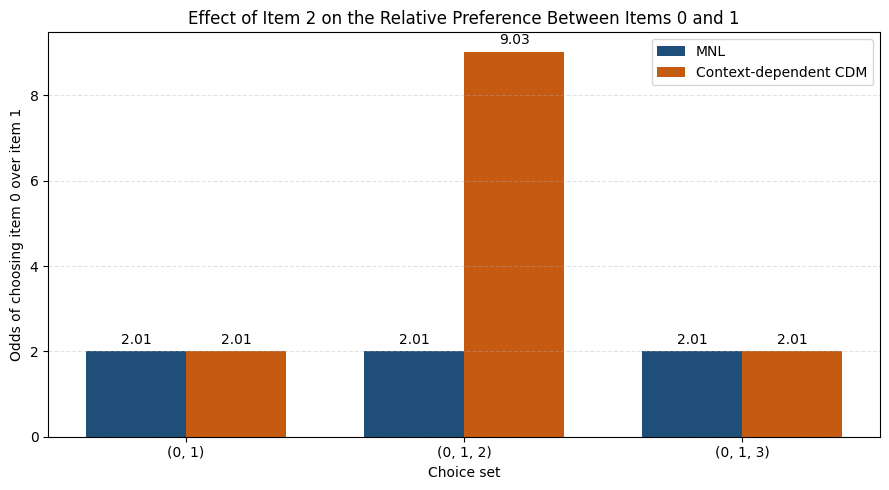

In [10]:
# Compare the relative odds of items 0 and 1 across choice sets.

plot_labels = [
    str(choice_set)
    for choice_set in context_effect_table["choice_set"]
]

horizontal_positions = np.arange(
    len(context_effect_table)
)

bar_width = 0.36

figure, axis = plt.subplots(figsize=(9, 5))

mnl_bars = axis.bar(
    horizontal_positions - bar_width / 2,
    context_effect_table["MNL odds P(0)/P(1)"],
    width=bar_width,
    color="#1F4E79",
    label="MNL",
)

cdm_bars = axis.bar(
    horizontal_positions + bar_width / 2,
    context_effect_table["CDM odds P(0)/P(1)"],
    width=bar_width,
    color="#C55A11",
    label="Context-dependent CDM",
)

axis.bar_label(
    mnl_bars,
    fmt="%.2f",
    padding=3,
)

axis.bar_label(
    cdm_bars,
    fmt="%.2f",
    padding=3,
)

axis.set_xticks(
    horizontal_positions,
    plot_labels,
)

axis.set_xlabel("Choice set")
axis.set_ylabel("Odds of choosing item 0 over item 1")
axis.set_title("Effect of Item 2 on the Relative Preference Between Items 0 and 1")
axis.legend()
axis.grid(
    True,
    axis="y",
    linestyle="--",
    alpha=0.35,
)

plt.tight_layout()
plt.show()